# 04 · Cost-based threshold and final test evaluation

**Goal:** turn model scores into alert decisions by choosing the threshold that
minimises expected cost, then measure the final models **once** on the held-out
test set.

- Thresholds are chosen on the **validation** set only (sections 2 and 3).
- Everything is frozen before section 4, where the **test set is used for the
  first and only time**.
- The headline model is the **pre-transaction XGBoost** from notebook 03 (uses
  only information available before the payment). The logistic regressions are
  included because, unlike the near-perfect XGBoost, they show how much the
  threshold choice can matter.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "CLAUDE.md").exists())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import load_data
from src.features import filter_relevant, default_boundaries, time_split, build_features
from src.models import make_logreg_baseline, full_balance_rule, SEED
from src.train import load_model
from src.evaluate import evaluate_model, plot_pr_curve, plot_confusion_matrix, save_metrics
from src.threshold import (cost_curve, best_threshold, cost_of_flagging_nothing,
                           plot_cost_curves, plot_threshold_sensitivity)
from src.plotting import set_style

np.random.seed(SEED)
set_style()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

## 1. Data and models

In [2]:
df = load_data(money_dtype="float64")
df = filter_relevant(df, verbose=False)
train_end, val_end = default_boundaries(df["step"])
train, val, test = time_split(df, train_end, val_end)
del df
# `test` is not looked at until section 4.

y_train, y_val = train["isFraud"].astype(int), val["isFraud"].astype(int)
X_train = {fs: build_features(train, feature_set=fs) for fs in ["full", "pre_transaction"]}
X_val = {fs: build_features(val, feature_set=fs) for fs in ["full", "pre_transaction"]}

# Headline model, trained in notebook 03 (no retraining here).
xgb = load_model("xgb_pre_transaction")
# Logistic regressions are quick to refit with the same settings as before.
logreg = {fs: make_logreg_baseline().fit(X_train[fs], y_train) for fs in ["full", "pre_transaction"]}

MODELS = {
    "XGBoost (pre-transaction)": (xgb, "pre_transaction"),
    "Logistic regression (pre-transaction)": (logreg["pre_transaction"], "pre_transaction"),
    "Logistic regression (full, notebook 02 baseline)": (logreg["full"], "full"),
}
val_scores = {name: m.predict_proba(X_val[fs])[:, 1] for name, (m, fs) in MODELS.items()}
for name, s in val_scores.items():
    print(f"{name:<50} validation PR-AUC {evaluate_model(y_val, s)['pr_auc']:.4f}")

train steps   1-520  2,653,729 rows |  5,781 fraud | fraud rate 0.2178%
val   steps 521-632     78,709 rows |  1,188 fraud | fraud rate 1.5094%
test  steps 633-743     37,971 rows |  1,244 fraud | fraud rate 3.2762%


XGBoost (pre-transaction)                          validation PR-AUC 1.0000
Logistic regression (pre-transaction)              validation PR-AUC 0.4341
Logistic regression (full, notebook 02 baseline)   validation PR-AUC 0.8786


## 2. Choosing the threshold on validation

**Cost assumptions** (illustrative, not taken from the data):

| | Cost | Reasoning |
|---|---|---|
| **Missed fraud** (false negative) | **500** | average loss written off per undetected fraud |
| **False alarm** (false positive) | **5** | analyst review time plus friction for a genuine customer |

So a missed fraud is assumed to cost **100 times** as much as a false alarm. The
best threshold depends only on this ratio, not on the absolute amounts. Real
values would come from the bank's loss and operations data; section 3 checks how
sensitive the choice is to this assumption.

Total cost = 500 × missed frauds + 5 × false alarms. Flagging nothing at all
costs 500 × (number of frauds).

In [3]:
COST_FN, COST_FP = 500, 5

curves, chosen = {}, {}
rows = []
for name, scores in val_scores.items():
    curves[name] = cost_curve(y_val, scores, COST_FN, COST_FP)
    chosen[name], best = best_threshold(y_val, scores, COST_FN, COST_FP)
    at_05 = curves[name].loc[curves[name]["threshold"] == 0.5].iloc[0]
    rows.append({"model": name, "chosen threshold": chosen[name],
                 "cost at chosen": best["total_cost"], "FP at chosen": int(best["fp"]), "FN at chosen": int(best["fn"]),
                 "cost at 0.5": at_05["total_cost"], "FP at 0.5": int(at_05["fp"]), "FN at 0.5": int(at_05["fn"])})

print(f"Validation: {len(y_val):,} rows, {int(y_val.sum()):,} frauds. "
      f"Flagging nothing would cost {cost_of_flagging_nothing(y_val, COST_FN):,.0f}.")
pd.DataFrame(rows).set_index("model")

Validation: 78,709 rows, 1,188 frauds. Flagging nothing would cost 594,000.


,chosen threshold,cost at chosen,FP at chosen,FN at chosen,cost at 0.5,FP at 0.5,FN at 0.5
model,,,,,,,
XGBoost (pre-transaction),0.3940,0.0000,0,0,"1,000.0000",0,2
Logistic regression (pre-transaction),0.3470,"101,110.0000",16622,36,"109,175.0000",11335,105
"Logistic regression (full, notebook 02 baseline)",0.5740,"33,975.0000",3595,32,"36,705.0000",5341,20


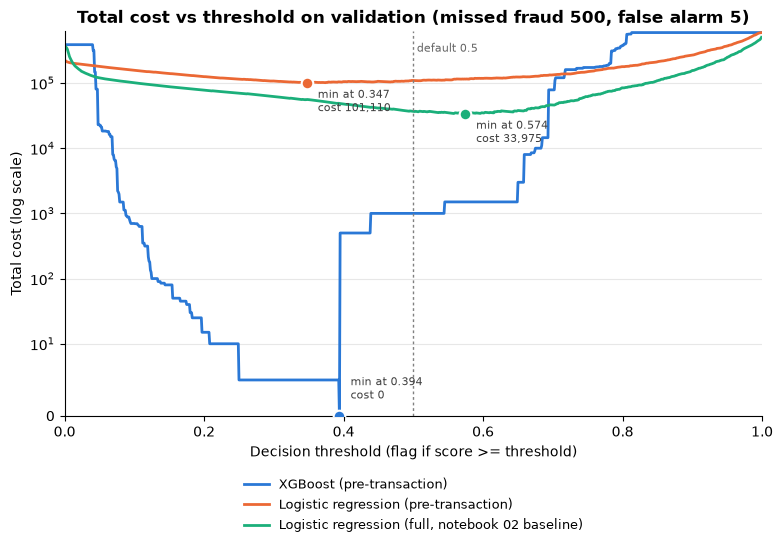

In [4]:
fig = plot_cost_curves(
    {name: (curves[name], chosen[name]) for name in MODELS},
    title="Total cost vs threshold on validation (missed fraud 500, false alarm 5)",
    name="cost_vs_threshold",
)
plt.show()

## 3. Sensitivity to the cost assumption

The 100:1 ratio is an assumption, so the threshold is re-optimised for missed-fraud
to false-alarm cost ratios of 10:1, 50:1, 100:1 and 500:1 (false alarm cost fixed
at 1; only the ratio matters).

In [5]:
RATIOS = [10, 50, 100, 500]
sens_rows = []
for name, scores in val_scores.items():
    for ratio in RATIOS:
        t, row = best_threshold(y_val, scores, cost_fn=ratio, cost_fp=1)
        sens_rows.append({"model": name, "fn_fp_ratio": ratio, "best_threshold": t,
                          "precision": row["precision"], "recall": row["recall"],
                          "false alarms": int(row["fp"]), "missed frauds": int(row["fn"]),
                          "alerts per fraud caught": row["n_alerts"] / row["tp"] if row["tp"] else np.nan})
sensitivity = pd.DataFrame(sens_rows)
sensitivity.set_index(["model", "fn_fp_ratio"])

best_threshold  \
model                                            fn_fp_ratio                   
XGBoost (pre-transaction)                        10                   0.3940   
                                                 50                   0.3940   
                                                 100                  0.3940   
                                                 500                  0.3940   
Logistic regression (pre-transaction)            10                   0.8590   
                                                 50                   0.6320   
                                                 100                  0.3470   
                                                 500                  0.2240   
Logistic regression (full, notebook 02 baseline) 10                   0.7680   
                                                 50                   0.6430   
                                                 100                  0.5740   
                                                 500                  0.4390   

                                                              precision  \
model                                            fn_fp_ratio              
XGBoost (pre-transaction)                        10              1.0000   
                                                 50              1.0000   
                                                 100             1.0000   
                                                 500             1.0000   
Logistic regression (pre-transaction)            10              0.2867   
                                                 50              0.1210   
                                                 100             0.0648   
                                                 500             0.0497   
Logistic regression (full, notebook 02 baseline) 10              0.5723   
                                                 50              0.3320   
                                                 100             0.2433   
                                                 500             0.1443   

                                                              recall  \
model                                            fn_fp_ratio           
XGBoost (pre-transaction)                        10           1.0000   
                                                 50           1.0000   
                                                 100          1.0000   
                                                 500          1.0000   
Logistic regression (pre-transaction)            10           0.6473   
                                                 50           0.8620   
                                                 100          0.9697   
                                                 500          0.9882   
Logistic regression (full, notebook 02 baseline) 10           0.8931   
                                                 50           0.9588   
                                                 100          0.9731   
                                                 500          0.9874   

                                                              false alarms  \
model                                            fn_fp_ratio                 
XGBoost (pre-transaction)                        10                      0   
                                                 50                      0   
                                                 100                     0   
                                                 500                     0   
Logistic regression (pre-transaction)            10                   1913   
                                                 50                   7438   
                                                 100                 16622   
                                                 500                 22434   
Logistic regression (full, notebook 02 baseline) 10                    793   
                       

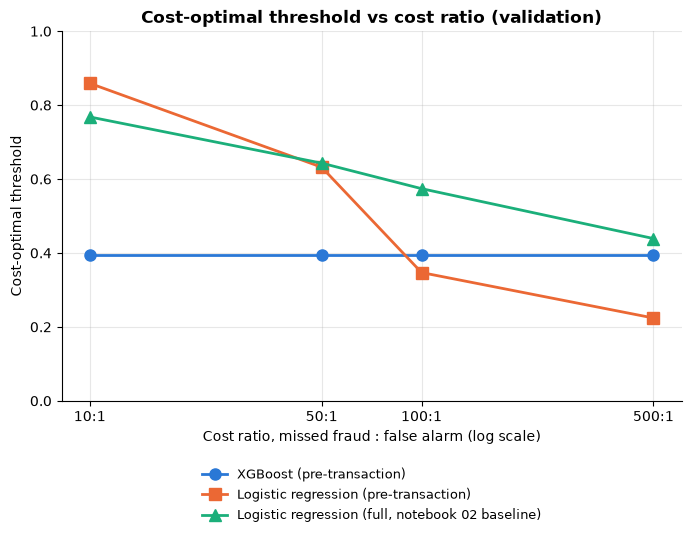

In [6]:
fig = plot_threshold_sensitivity(
    sensitivity,
    title="Cost-optimal threshold vs cost ratio (validation)",
    name="threshold_sensitivity",
)
plt.show()

## 4. Final evaluation on the test set (used once)

Everything is now frozen: the models (trained on train, selected on validation)
and the thresholds (chosen on validation at 100:1). The test set covers steps
633 to 743 and has **not been used anywhere before this point**. Each model is
scored at its validation-chosen threshold, at the default 0.5, and against
flagging nothing. The one-line rule from notebook 03 is included for reference.

In [7]:
frozen_thresholds = dict(chosen)   # fixed before looking at test

y_test = test["isFraud"].astype(int)
X_test = {fs: build_features(test, feature_set=fs) for fs in ["full", "pre_transaction"]}
test_scores = {name: m.predict_proba(X_test[fs])[:, 1] for name, (m, fs) in MODELS.items()}
nothing_cost = cost_of_flagging_nothing(y_test, COST_FN)
print(f"Test: {len(y_test):,} rows, {int(y_test.sum()):,} frauds, base rate {y_test.mean():.4%}. "
      f"Flagging nothing costs {nothing_cost:,.0f}.")

def result_row(model, decision, scores, threshold):
    m = evaluate_model(y_test, scores, threshold)
    cost = COST_FN * m["fn"] + COST_FP * m["fp"]
    return {"model": model, "decision rule": decision, "threshold": threshold,
            "pr_auc": m["pr_auc"], "precision": m["precision"], "recall": m["recall"], "f1": m["f1"],
            "tp": m["tp"], "fp": m["fp"], "fn": m["fn"], "tn": m["tn"],
            "total_cost": cost, "savings_vs_flag_nothing": nothing_cost - cost,
            "savings_pct": 100 * (nothing_cost - cost) / nothing_cost}

final_rows, test_metrics = [], {}
for name in MODELS:
    t = frozen_thresholds[name]
    final_rows.append(result_row(name, "validation-optimal threshold", test_scores[name], t))
    final_rows.append(result_row(name, "default threshold 0.5", test_scores[name], 0.5))
    test_metrics[name] = evaluate_model(y_test, test_scores[name], t)
final_rows.append(result_row("One-line rule (amount = full origin balance)", "rule (0/1)",
                             full_balance_rule(test), 0.5))
final_rows.append({"model": "Flag nothing", "decision rule": "never alert", "threshold": np.nan,
                   "pr_auc": y_test.mean(), "precision": np.nan, "recall": 0.0, "f1": 0.0,
                   "tp": 0, "fp": 0, "fn": int(y_test.sum()), "tn": int((y_test == 0).sum()),
                   "total_cost": nothing_cost, "savings_vs_flag_nothing": 0.0, "savings_pct": 0.0})

final_results = pd.DataFrame(final_rows)
final_results.to_csv(ROOT / "reports" / "final_results.csv", index=False)
print("Saved reports/final_results.csv")
final_results.set_index(["model", "decision rule"])[
    ["threshold", "pr_auc", "precision", "recall", "f1", "fp", "fn", "total_cost", "savings_pct"]]

Test: 37,971 rows, 1,244 frauds, base rate 3.2762%. Flagging nothing costs 622,000.


Saved reports/final_results.csv


threshold  \
model                                            decision rule                             
XGBoost (pre-transaction)                        validation-optimal threshold     0.3940   
                                                 default threshold 0.5            0.5000   
Logistic regression (pre-transaction)            validation-optimal threshold     0.3470   
                                                 default threshold 0.5            0.5000   
Logistic regression (full, notebook 02 baseline) validation-optimal threshold     0.5740   
                                                 default threshold 0.5            0.5000   
One-line rule (amount = full origin balance)     rule (0/1)                       0.5000   
Flag nothing                                     never alert                         NaN   

                                                                               pr_auc  \
model                                            decision rule                          
XGBoost (pre-transaction)                        validation-optimal threshold  0.9999   
                                                 default threshold 0.5         0.9999   
Logistic regression (pre-transaction)            validation-optimal threshold  0.5236   
                                                 default threshold 0.5         0.5236   
Logistic regression (full, notebook 02 baseline) validation-optimal threshold  0.9051   
                                                 default threshold 0.5         0.9051   
One-line rule (amount = full origin balance)     rule (0/1)                    0.9930   
Flag nothing                                     never alert                   0.0328   

                                                                               precision  \
model                                            decision rule                             
XGBoost (pre-transaction)                        validation-optimal threshold     1.0000   
                                                 default threshold 0.5            1.0000   
Logistic regression (pre-transaction)            validation-optimal threshold     0.1204   
                                                 default threshold 0.5            0.1623   
Logistic regression (full, notebook 02 baseline) validation-optimal threshold     0.3670   
                                                 default threshold 0.5            0.2901   
One-line rule (amount = full origin balance)     rule (0/1)                       1.0000   
Flag nothing                                     never alert                         NaN   

                                                                               recall  \
model                                            decision rule                          
XGBoost (pre-transaction)                        validation-optimal threshold  0.9992   
                                                 default threshold 0.5         0.9960   
Logistic regression (pre-transaction)            validation-optimal threshold  0.9614   
                                                 default threshold 0.5         0.9156   
Logistic regression (full, notebook 02 baseline) validation-optimal threshold  0.9630   
                                                 default threshold 0.5         0.9743   
One-line rule (amount = full origin balance)     rule (0/1)                    0.9928   
Flag nothing                                     never alert                   0.0000   

                                                                                  f1  \
model                                            decision rule                         
XGBoost (pre-transaction)                        validation-optimal threshold 0.9996   
                                                 default threshold 0.5        0.9980   
Logistic regression (pre-transaction)            validation-optimal threshold 0.2141   
               

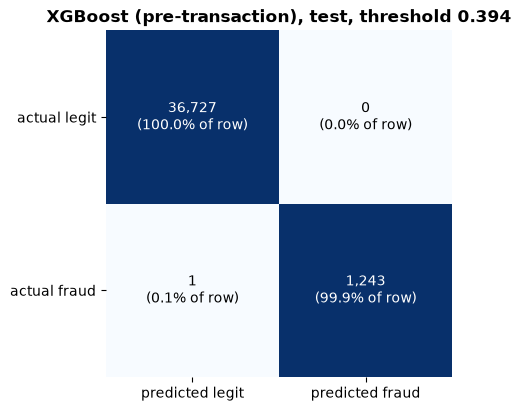

In [8]:
headline = "XGBoost (pre-transaction)"
fig = plot_confusion_matrix(
    test_metrics[headline]["confusion_matrix"],
    title=f"XGBoost (pre-transaction), test, threshold {frozen_thresholds[headline]:.3f}",
    name="test_confusion_matrix",
)
plt.show()

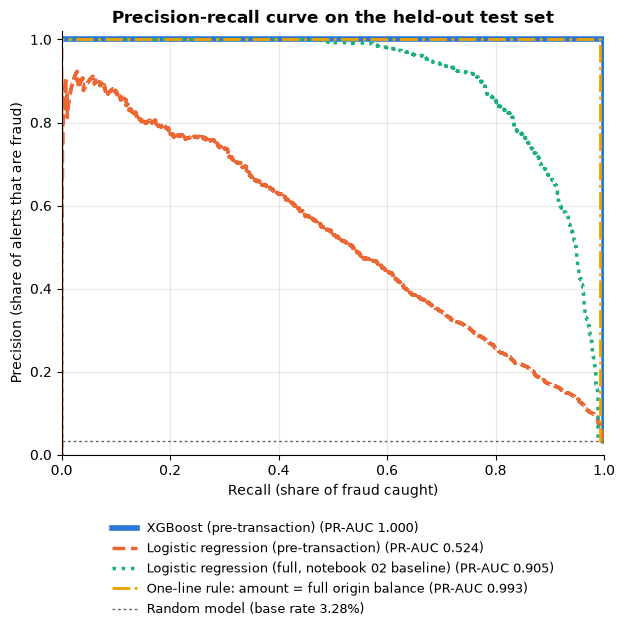

In [9]:
fig = plot_pr_curve(
    {"XGBoost (pre-transaction)": (y_test, test_scores["XGBoost (pre-transaction)"]),
     "Logistic regression (pre-transaction)": (y_test, test_scores["Logistic regression (pre-transaction)"]),
     "Logistic regression (full, notebook 02 baseline)": (y_test, test_scores["Logistic regression (full, notebook 02 baseline)"]),
     "One-line rule: amount = full origin balance": (y_test, full_balance_rule(test))},
    title="Precision-recall curve on the held-out test set",
    name="final_test_pr_curve",
)
plt.show()

In [10]:
save_metrics(
    {"cost_assumptions": {"cost_fn": COST_FN, "cost_fp": COST_FP},
     "thresholds_chosen_on_validation": frozen_thresholds,
     "test": {"rows": int(len(y_test)), "frauds": int(y_test.sum()), "base_rate": float(y_test.mean()),
              "metrics_at_chosen_threshold": test_metrics}},
    ROOT / "reports" / "final_metrics.json",
)
print("Saved reports/final_metrics.json")

Saved reports/final_metrics.json


## Summary

**Choosing the threshold (validation, missed fraud : false alarm = 100:1)**

- **XGBoost:** a threshold of **0.394** gives **zero cost** on validation: every
  fraud caught, no false alarms. The choice does not move at all with the cost
  ratio (0.394 from 10:1 to 500:1), because the model separates the classes so
  cleanly that there is no trade-off left to make. With only 3 trees its scores
  take few distinct values, so the zero-cost region is a wide plateau.
- **Logistic regression shows what a threshold normally does.** As a missed
  fraud becomes more expensive, the best threshold falls (pre-transaction: 0.859
  at 10:1 down to 0.224 at 500:1; full features: 0.768 down to 0.439), trading
  more false alarms for fewer misses. At 100:1 the pre-transaction model accepts
  16,622 false alarms to catch 97% of fraud. The cost assumption effectively
  decides how much review work the bank signs up for.

**Final test results (used once: 37,971 transactions, 1,244 frauds, base rate 3.28%)**

| Model | Threshold | Precision | Recall | False alarms | Missed | Total cost | Saving vs flag nothing |
|---|---|---|---|---|---|---|---|
| XGBoost (pre-transaction) | 0.394 (validation) | 100% | 99.92% | 0 | 1 | 500 | 621,500 (99.9%) |
| XGBoost (pre-transaction) | 0.5 | 100% | 99.60% | 0 | 5 | 2,500 | 619,500 (99.6%) |
| One-line rule | – | 100% | 99.28% | 0 | 9 | 4,500 | 617,500 (99.3%) |
| Logistic regression (full) | 0.574 (validation) | 36.7% | 96.3% | 2,066 | 46 | 33,330 | 588,670 (94.6%) |
| Logistic regression (full) | 0.5 | 29.0% | 97.4% | 2,966 | 32 | 30,830 | 591,170 (95.0%) |
| Logistic regression (pre-transaction) | 0.347 (validation) | 12.0% | 96.1% | 8,734 | 48 | 67,670 | 554,330 (89.1%) |
| Logistic regression (pre-transaction) | 0.5 | 16.2% | 91.6% | 5,880 | 105 | 81,900 | 540,100 (86.8%) |
| Flag nothing | – | – | 0% | 0 | 1,244 | 622,000 | – |

- The cost-optimal threshold **beat 0.5 for XGBoost** (500 vs 2,500) and for the
  pre-transaction logistic regression (17% lower cost).
- For the full-feature logistic regression it did **slightly worse** than 0.5 on
  test (33,330 vs 30,830). The test period has twice the validation fraud rate
  (3.28% vs 1.51%). With fraud more common, misses dominate the total cost and a
  lower threshold would have been better. A threshold tuned at one fraud rate does
  not transfer perfectly when that rate shifts, so in production it would need
  monitoring and periodic re-tuning.

### ⚠ Warning: these test scores are suspiciously high

A PR-AUC of 0.9999, zero false alarms and one missed fraud out of 1,244 is **not
believable for real fraud detection**, where models routinely trade many false
alarms for recall. The likely reasons:

1. **Synthetic data with a simple fraud rule.** In PaySim, fraud always moves the
   origin account's entire balance and no legitimate transaction does. The
   one-line rule alone catches 99.3% of test fraud with zero false alarms.
   XGBoost has learned this rule from the simulator, not general fraud behaviour.
2. **A high test fraud rate.** Fraud is 3.28% of the test period, 15 times the
   training rate, which pushes precision up.
3. **The savings inherit both problems**, and they rest on assumed costs (500 and
   5). On real data, expect far lower recall at the same alert volume.

**What the result does show:** the evaluation pipeline is sound. With a
time-based split, thresholds frozen on validation and a single look at the test
set, performance carried over to a later period without degrading. The cost
framework also changes decisions where the model is imperfect, which is the
situation a bank would actually be in.